<a href="https://colab.research.google.com/github/zhiyuguo-innis/MSSP607/blob/main/WeeklyModules/Week08/PARTICIPATION_ACTIVITY_Week_8_Plot_a_trendline_over_a_time_series_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Participation Activity Week 8: Plot a Trendline over a Time Series Dataset
**MSSP 607** · Zhiyu Guo


## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import statsmodels.api as sm

pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
BLUE, ORANGE, GREY = '#2a78d6', '#eb6834', '#52514e'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e5e5e2', 'axes.axisbelow': True, 'axes.titlelocation': 'left'})
millions = FuncFormatter(lambda v, _: f'${v/1e6:g}M')

## 2. Load the Internet Sales data
The CSV is stored in my repository (`zhiyuguo-innis/MSSP607`, folder `data/`) and read through its raw GitHub URL.
The file is Latin-1 encoded (some city names have accented letters), so `encoding='latin-1'` is needed.

In [2]:
DATA_URL = 'https://raw.githubusercontent.com/zhiyuguo-innis/MSSP607/main/data/InternetSales.csv'
LOCAL_COPY = 'InternetSales.csv'   # only used if GitHub cannot be reached
try:
    sales = pd.read_csv(DATA_URL, encoding='latin-1', low_memory=False)
    print('Loaded from GitHub:', DATA_URL)
except Exception as err:
    print('GitHub read failed (', type(err).__name__, ') - reading local copy instead.')
    sales = pd.read_csv(LOCAL_COPY, encoding='latin-1', low_memory=False)

sales['OrderDate'] = pd.to_datetime(sales['OrderDate'], format='%m/%d/%Y')
sales['OrderYear'] = sales['OrderDate'].dt.year
print('Shape:', sales.shape)
print('Orders from', sales['OrderDate'].min().date(), 'to', sales['OrderDate'].max().date())
sales[['SalesOrderNumber', 'OrderDate', 'EnglishProductName', 'SalesAmount']].head()

Loaded from GitHub: https://raw.githubusercontent.com/zhiyuguo-innis/MSSP607/main/data/InternetSales.csv
Shape: (60398, 61)
Orders from 2010-12-29 to 2014-01-28


,SalesOrderNumber,OrderDate,EnglishProductName,SalesAmount
0,SO43793,2011-01-19,"Mountain-100 Silver, 38","3,399.99"
1,SO51522,2013-01-18,"Mountain-200 Silver, 38","2,319.99"
2,SO51522,2013-01-18,Fender Set - Mountain,21.98
3,SO57418,2013-05-03,"Touring-1000 Blue, 46","2,384.07"
4,SO57418,2013-05-03,Touring Tire,28.99


## 3. Build the monthly sales series
The first month (Dec 2010: only the 29th–31st) and the last month (Jan 2014: 1st–28th, with no bike sales)
are incomplete, so the series uses the 36 complete months from January 2011 to December 2013.

In [3]:
monthly = (sales.set_index('OrderDate')['SalesAmount'].resample('MS').sum()
           .loc['2011-01-01':'2013-12-01'].to_frame('Sales'))
monthly['t'] = np.arange(1, len(monthly) + 1)     # month number 1..36, used as the trend variable
print('Months in the series:', len(monthly))
monthly.describe()

Months in the series: 36


,Sales,t
count,36.00,36.00
mean,"813,043.37",18.50
std,"451,340.89",10.54
min,"358,877.89",1.00
25%,"500,396.42",9.75
50%,"608,820.72",18.50
75%,"1,046,993.93",27.25
max,"1,874,360.29",36.00


## 4. Trend line on the sales
A linear trend line is fitted by ordinary least squares: **Sales = a + b × month**.
The slope *b* is the average change in monthly sales per month.

In [4]:
X = sm.add_constant(monthly['t'])
trend = sm.OLS(monthly['Sales'], X).fit()
a, b = trend.params['const'], trend.params['t']
monthly['Trend'] = trend.fittedvalues

print(f'Trend line: Sales = {a:,.0f} + {b:,.0f} x month')
print(f'Monthly sales rise by about ${b:,.0f} per month on average (p = {trend.pvalues["t"]:.2g}); R-squared = {trend.rsquared:.3f}')

Trend line: Sales = 195,270 + 33,393 x month
Monthly sales rise by about $33,393 per month on average (p = 2.1e-08); R-squared = 0.608


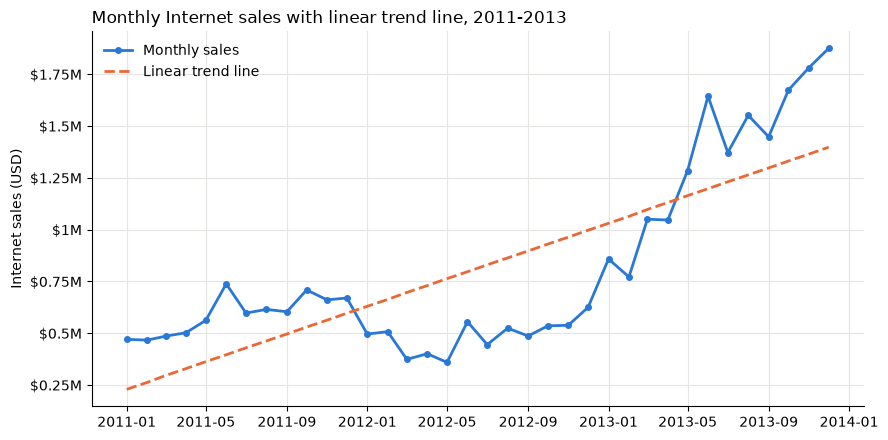

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(monthly.index, monthly['Sales'], color=BLUE, lw=2, marker='o', ms=4, label='Monthly sales')
ax.plot(monthly.index, monthly['Trend'], color=ORANGE, lw=2, ls='--', label='Linear trend line')
ax.yaxis.set_major_formatter(millions)
ax.set_ylabel('Internet sales (USD)')
ax.set_title('Monthly Internet sales with linear trend line, 2011-2013')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## 5. Five-year forecast (2014–2018)
The trend line is extended 60 months ahead (months 37–96). The shaded band is the 95% prediction interval
from the regression, which shows how uncertain a single future month is.

In [5]:
future = pd.DataFrame({'t': np.arange(len(monthly) + 1, len(monthly) + 61)},
                      index=pd.date_range('2014-01-01', periods=60, freq='MS'))
pred = trend.get_prediction(sm.add_constant(future['t'], has_constant='add')).summary_frame(alpha=0.05)
future['Forecast'] = pred['mean'].values
future['Lower 95%'] = pred['obs_ci_lower'].values
future['Upper 95%'] = pred['obs_ci_upper'].values

# Annual totals: actual 2011-2013 and forecast 2014-2018
actual_year = monthly['Sales'].groupby(monthly.index.year).sum()
forecast_year = future[['Forecast', 'Lower 95%', 'Upper 95%']].groupby(future.index.year).sum()
annual = pd.concat([actual_year.rename('Actual'), forecast_year], axis=1)
annual.index.name = 'Year'
annual['Growth vs prior year (%)'] = annual['Actual'].fillna(annual['Forecast']).pct_change() * 100
annual.round(0)

,Actual,Forecast,Lower 95%,Upper 95%,Growth vs prior year (%)
Year,,,,,
2011,"7,075,526.00",NaN,NaN,NaN,NaN
2012,"5,842,485.00",NaN,NaN,NaN,-17.00
2013,"16,351,550.00",NaN,NaN,NaN,180.00
2014,NaN,"19,373,754.00","11,778,928.00","26,968,581.00",18.00
2015,NaN,"24,182,371.00","16,013,361.00","32,351,381.00",25.00
2016,NaN,"28,990,988.00","20,079,680.00","37,902,295.00",20.00
2017,NaN,"33,799,604.00","24,015,965.00","43,583,244.00",17.00
2018,NaN,"38,608,221.00","27,853,777.00","49,362,665.00",14.00


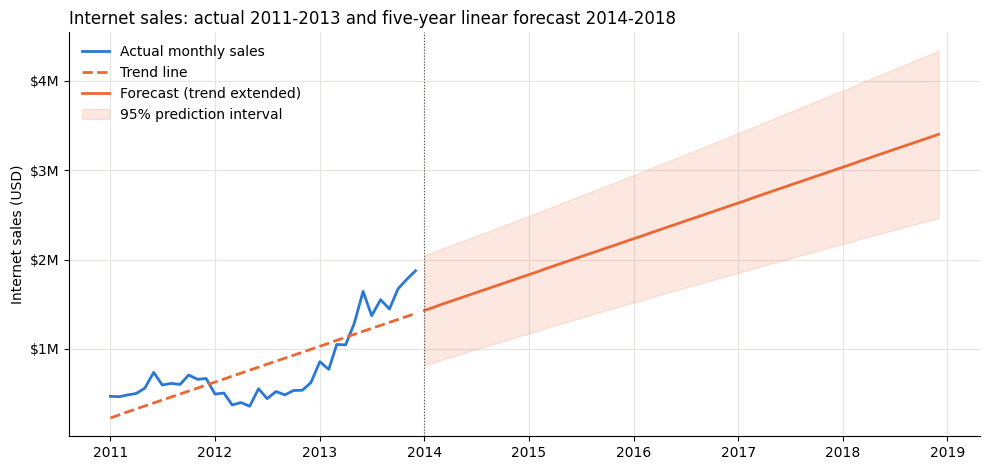

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(monthly.index, monthly['Sales'], color=BLUE, lw=2, label='Actual monthly sales')
ax.plot(monthly.index, monthly['Trend'], color=ORANGE, lw=2, ls='--', label='Trend line')
ax.plot(future.index, future['Forecast'], color=ORANGE, lw=2, label='Forecast (trend extended)')
ax.fill_between(future.index, future['Lower 95%'], future['Upper 95%'], color=ORANGE, alpha=0.15,
                label='95% prediction interval')
ax.axvline(pd.Timestamp('2014-01-01'), color=GREY, lw=0.8, ls=':')
ax.yaxis.set_major_formatter(millions)
ax.set_ylabel('Internet sales (USD)')
ax.set_title('Internet sales: actual 2011-2013 and five-year linear forecast 2014-2018')
ax.legend(frameon=False, loc='upper left')
fig.tight_layout()
plt.show()

**Reading the forecast.** If sales keep rising along the 2011–2013 trend line, annual Internet sales reach the
levels in the table above by 2018. This forecast should be read with caution:

* It rests on only 36 months of data, and most of the growth comes from a single jump in early 2013, when
  Adventure Works added accessories, clothing, and lower-priced bikes. A straight line treats that one-off
  launch as if it were steady growth.
* Because the 2011–2012 months sit well above or below the line, the trend underpredicts late 2013
  (December 2013 sales were about $1.87M) and the prediction interval is wide.
* A linear trend has no seasonality, and the data are fictitious, so the forecast illustrates the method only.

In [7]:
# How well does the line fit the most recent months?
check = monthly.loc['2013-07-01':, ['Sales', 'Trend']].copy()
check['Gap (actual - trend)'] = check['Sales'] - check['Trend']
check

,Sales,Trend,Gap (actual - trend)
OrderDate,,,
2013-07-01,"1,371,675.81","1,230,458.03","141,217.78"
2013-08-01,"1,551,065.56","1,263,851.20","287,214.36"
2013-09-01,"1,447,495.69","1,297,244.37","150,251.32"
2013-10-01,"1,673,293.41","1,330,637.54","342,655.87"
2013-11-01,"1,780,920.06","1,364,030.71","416,889.35"
2013-12-01,"1,874,360.29","1,397,423.89","476,936.40"


## 6. Which product generates the most sales?
I compare products on summary statistics of `SalesAmount`: total sales, number of units, mean and median price,
and standard deviation. Each row of the data is one unit (`OrderQuantity` is always 1).

In [8]:
product_stats = (sales.groupby('EnglishProductName')['SalesAmount']
                 .agg(TotalSales='sum', Units='count', MeanPrice='mean', MedianPrice='median', SD='std')
                 .sort_values('TotalSales', ascending=False))
product_stats['Share of sales (%)'] = product_stats['TotalSales'] / product_stats['TotalSales'].sum() * 100
print('Products:', len(product_stats))
product_stats.head(10)

Products: 130


,TotalSales,Units,MeanPrice,MedianPrice,SD,Share of sales (%)
EnglishProductName,,,,,,
"Mountain-200 Black, 46","1,373,469.55",620,"2,215.27","2,294.99",115.19,4.68
"Mountain-200 Black, 42","1,363,142.09",614,"2,220.10","2,294.99",113.26,4.64
"Mountain-200 Silver, 38","1,339,462.79",596,"2,247.42","2,319.99",113.11,4.56
"Mountain-200 Silver, 46","1,301,100.10",580,"2,243.28","2,319.99",114.92,4.43
"Mountain-200 Black, 38","1,294,866.14",582,"2,224.86","2,294.99",111.12,4.41
"Mountain-200 Silver, 42","1,257,434.57",560,"2,245.42","2,319.99",114.01,4.28
"Road-150 Red, 48","1,205,876.99",337,"3,578.27","3,578.27",0.00,4.11
"Road-150 Red, 62","1,202,298.72",336,"3,578.27","3,578.27",0.00,4.10
"Road-150 Red, 52","1,080,637.54",302,"3,578.27","3,578.27",0.00,3.68


In [9]:
# Product names include colour and frame size (e.g. 'Mountain-200 Black, 46'); the model is 'Mountain-200'.
# Grouping by model gives a clearer picture of which product line earns the most.
sales['Model'] = (sales['EnglishProductName'].str.split(',').str[0]
                  .str.replace(r' (Black|Silver|Red|Yellow|Blue)$', '', regex=True))   # drop colour too
model_stats = (sales.groupby('Model')['SalesAmount']
               .agg(TotalSales='sum', Units='count', MeanPrice='mean', SD='std')
               .sort_values('TotalSales', ascending=False))
model_stats['Share of sales (%)'] = model_stats['TotalSales'] / model_stats['TotalSales'].sum() * 100

# 'Will generate' looks forward, so check which models are still selling in the most recent full year
model_by_year = sales.pivot_table(index='Model', columns='OrderYear', values='SalesAmount', aggfunc='sum', fill_value=0)
model_stats = model_stats.join(model_by_year[[2011, 2012, 2013]].add_prefix('Sales '))
model_stats.head(10)

,TotalSales,Units,MeanPrice,SD,Share of sales (%),Sales 2011,Sales 2012,Sales 2013
Model,,,,,,,,
Mountain-200,"7,929,475.24",3552,"2,232.40",114.29,27.01,"8,218.71","2,261,546.06","5,659,710.47"
Road-150,"5,549,896.77",1551,"3,578.27",0.00,18.90,"5,524,848.88",0.00,0.00
Road-250,"4,451,260.12",1903,"2,339.08",128.19,15.16,"34,294.16","2,718,837.71","1,698,128.25"
Touring-1000,"2,992,007.85",1255,"2,384.07",0.00,10.19,0.00,"14,304.42","2,977,703.43"
Road-350-W,"1,580,219.71",929,"1,700.99",0.00,5.38,0.00,"8,504.95","1,571,714.76"
Road-550-W,"1,514,622.36",1390,"1,089.66",52.47,5.16,"2,000.88","359,637.27","1,152,984.21"
Mountain-100,"1,341,121.04",396,"3,386.67",12.49,4.57,"1,324,146.09",0.00,0.00
Road-750,"779,205.57",1443,539.99,0.00,2.65,0.00,"5,939.89","773,265.68"
Road-650,"645,379.50",852,757.49,38.61,2.20,"182,017.21","461,964.10",0.00


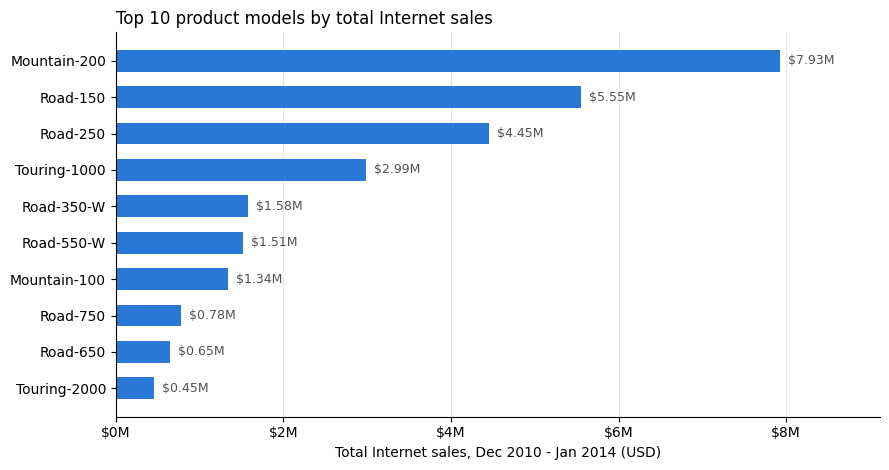

Top single product: Mountain-200 Black, 46 ($1,373,469.55)
Top model: Mountain-200 ($7,929,475.24, 27.0% of all sales)
Top model in 2013, the most recent full year: Mountain-200 ($5,659,710.47)


In [10]:
top10 = model_stats.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(top10.index, top10['TotalSales'], color=BLUE, height=0.6)
for y, v in enumerate(top10['TotalSales']):
    ax.text(v, y, f'  ${v/1e6:,.2f}M', va='center', fontsize=9, color=GREY)
ax.xaxis.set_major_formatter(millions)
ax.set_xlabel('Total Internet sales, Dec 2010 - Jan 2014 (USD)')
ax.set_title('Top 10 product models by total Internet sales')
ax.grid(axis='y', visible=False)
ax.margins(x=0.15)
fig.tight_layout()
plt.show()

best_product = product_stats.index[0]
best_model = model_stats.index[0]
best_2013 = model_by_year[2013].idxmax()
print(f'Top single product: {best_product} (${product_stats.iloc[0]["TotalSales"]:,.2f})')
print(f'Top model: {best_model} (${model_stats.iloc[0]["TotalSales"]:,.2f}, '
      f'{model_stats.iloc[0]["Share of sales (%)"]:.1f}% of all sales)')
print(f'Top model in 2013, the most recent full year: {best_2013} (${model_by_year.loc[best_2013, 2013]:,.2f})')

## 7. Summary

* **Trend line.** Monthly Internet sales rose by about \$33,400 per month on average over 2011–2013
  (linear trend, R² = 0.61, p < .001).
* **Five-year forecast.** Extending the trend line gives annual Internet sales of about **\$19.4M in 2014**, rising to
  **\$38.6M in 2018** (95% prediction interval for 2018: \$27.9M–\$49.4M). Because most of the 2011–2013 growth
  came from the early-2013 product launch, and the line already sits about \$0.48M below actual December 2013 sales,
  this is an illustrative projection rather than a reliable prediction.
* **Product with the most sales.** By the summary statistics, the **Mountain-200** generates the most sales:
  \$7.93M in total (27.0% of all Internet sales, 3,552 units at a mean price of \$2,232). It is also the top
  model in 2013, the most recent full year (\$5.66M), and its sizes and colours fill the top six places of the
  single-product list, led by Mountain-200 Black, 46 (\$1.37M). Road-150 ranks second overall but was discontinued at
  the end of 2011, so it will not generate future sales.
